In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [15]:
data = pd.read_csv('ecommerce customers.csv', encoding='latin1')
data.head()

,Email,Address,Avatar,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank TunnelWrightmouth, MI 82180-9605",Violet,12.66,39.58,4.08,587.95
1,hduke@hotmail.com,"4547 Archer CommonDiazchester, CA 06566-8576",DarkGreen,11.11,37.27,2.66,392.20
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582Cobbborough, DC ...",Bisque,11.33,37.11,4.10,487.55
3,riverarebecca@gmail.com,"1414 David ThroughwayPort Jason, OH 22070-1220",SaddleBrown,13.72,36.72,3.12,581.85
4,mstephens@davidson-herman.com,"14023 Rodriguez PassagePort Jacobville, PR 372...",MediumAquaMarine,12.80,37.54,4.45,599.41


In [17]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    str    
 1   Address               500 non-null    str    
 2   Avatar                500 non-null    str    
 3   Time on App           500 non-null    float64
 4   Time on Website       500 non-null    float64
 5   Length of Membership  500 non-null    float64
 6   Yearly Amount Spent   500 non-null    float64
dtypes: float64(4), str(3)
memory usage: 27.5 KB


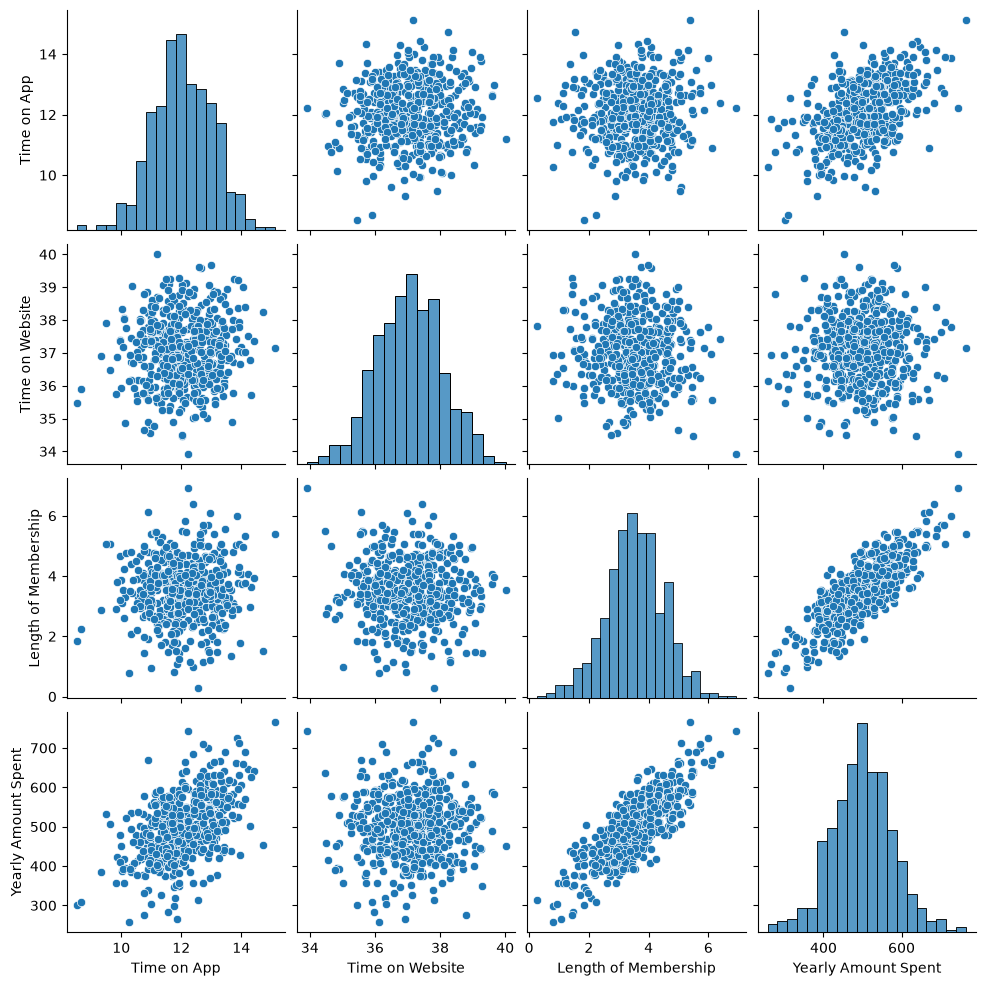

In [19]:
sns.pairplot(data=data)

In [20]:
#dropping unnnecery data
data.drop(columns=['Email','Address','Avatar'], inplace=True)
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Time on App           500 non-null    float64
 1   Time on Website       500 non-null    float64
 2   Length of Membership  500 non-null    float64
 3   Yearly Amount Spent   500 non-null    float64
dtypes: float64(4)
memory usage: 15.8 KB


In [21]:
feature = data.drop(columns=['Yearly Amount Spent'])
feature

,Time on App,Time on Website,Length of Membership
0,12.66,39.58,4.08
1,11.11,37.27,2.66
2,11.33,37.11,4.10
3,13.72,36.72,3.12
4,12.80,37.54,4.45
...,...,...,...
495,13.57,36.42,3.75
496,11.70,37.19,3.58
497,11.50,38.33,4.96
498,12.39,36.84,2.34


In [22]:
target = data['Yearly Amount Spent']
target

0      587.95
1      392.20
2      487.55
3      581.85
4      599.41
        ...  
495    573.85
496    529.05
497    551.62
498    456.47
499    497.78
Name: Yearly Amount Spent, Length: 500, dtype: float64

In [24]:
from sklearn.model_selection import train_test_split

In [25]:
x_train,x_test,y_train,y_test = train_test_split(feature,target,train_size=0.8 , random_state=45)

In [30]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[38.34,-0.39,62.85]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['Time on App','Time on Website','Length of Membership']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-171.4
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [31]:
model.coef_

array([38.34269183, -0.38540747, 62.84917273])

In [32]:
model.intercept_

np.float64(-171.4269047640754)

In [33]:
prediction = model.predict(x_test)

<Axes: xlabel='Yearly Amount Spent'>

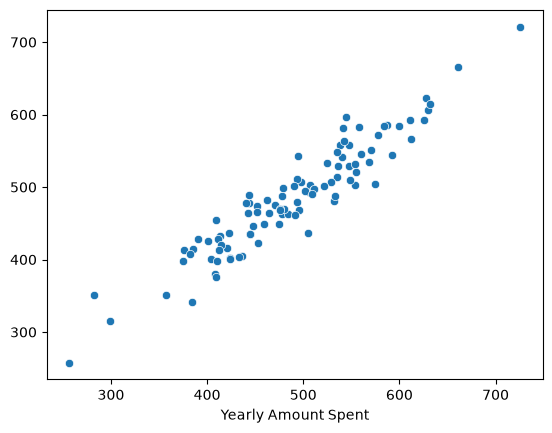

In [34]:
sns.scatterplot(x= y_test,y=prediction)

<Axes: xlabel='Yearly Amount Spent', ylabel='Count'>

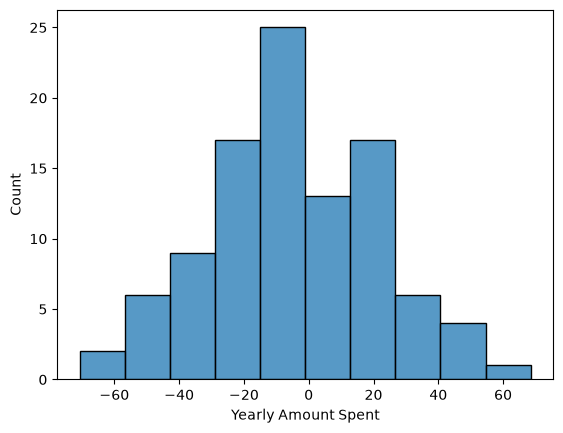

In [35]:
sns.histplot(x= prediction-y_test)

In [36]:
from sklearn.metrics import mean_absolute_error,mean_squared_error

mae = mean_absolute_error(y_test,prediction)
mae

21.75195191010044

In [37]:
mse = mean_squared_error(y_test,prediction)
mse

726.3670599632221

In [38]:
rmse = np.sqrt(mse)
rmse

np.float64(26.951197746356694)

In [40]:
pd.DataFrame(
    index=x_train.columns,
    data=model.coef_,
    columns=['coef']
)

,coef
Time on App,38.342692
Time on Website,-0.385407
Length of Membership,62.849173
